# PanEcho fine-tuning — calibration-ready run
Separate from the original notebook. Retains PanEcho and its fine-tuning loop. The official training split is divided into training and internal holdout; official validation is calibration-only; official test is untouched until final export. Identical deterministic multi-clip evaluation is used for calibration and test.

In [1]:
from pathlib import Path
import json
import hashlib
import random
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Open this notebook from inside your ml-service project.")
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.panecho_echonet_dataset import build_panecho_loaders, load_echonet_records
from src.models.echo.panecho import build_panecho_for_finetuning

def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''):digest.update(chunk)
    return digest.hexdigest()

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA available: True


In [2]:
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu');USE_AMP=DEVICE.type=='cuda';SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
BATCH_SIZE=1;NUM_WORKERS=0;EPOCHS=30;PATIENCE=7;EVAL_NUM_CLIPS=1


In [3]:
MANIFEST_PATH=PROJECT_ROOT/'data/processed/echo/echonet/echonet_panecho_manifest.csv'
PRETRAINED_CHECKPOINT=PROJECT_ROOT/'checkpoints/echo/panecho/pretrained/v1/model.pt'
LEGACY_PANECHO_CHECKPOINT=PROJECT_ROOT/'checkpoints/echo/panecho/pretrained/v1/model.pt'
OUTPUT_CHECKPOINT=PROJECT_ROOT/'checkpoints/echo/echonet/selected_panecho/v1/model.pt'
ARTIFACT_DIR=PROJECT_ROOT/'artifacts/03_training/echo/echonet/selected_panecho/v1'
OUTPUT_CHECKPOINT.parent.mkdir(parents=True,exist_ok=True);ARTIFACT_DIR.mkdir(parents=True,exist_ok=True)
if not MANIFEST_PATH.exists():raise FileNotFoundError(MANIFEST_PATH)
if not PRETRAINED_CHECKPOINT.exists() and LEGACY_PANECHO_CHECKPOINT.exists():PRETRAINED_CHECKPOINT=LEGACY_PANECHO_CHECKPOINT
if not PRETRAINED_CHECKPOINT.exists():raise FileNotFoundError(f'PanEcho weights not found. Expected {PRETRAINED_CHECKPOINT} or {LEGACY_PANECHO_CHECKPOINT}')


In [4]:
from sklearn.model_selection import GroupShuffleSplit
records=load_echonet_records(manifest=MANIFEST_PATH,project_root=PROJECT_ROOT)
train_pool=records.loc[records.split=='train'].copy().reset_index(drop=True)
calibration_records=records.loc[records.split=='val'].copy().reset_index(drop=True)
test_records=records.loc[records.split=='test'].copy().reset_index(drop=True)
splitter=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED)
tr,va=next(splitter.split(train_pool,groups=train_pool.video_path.map(lambda p:Path(p).stem)))
train_records=train_pool.iloc[tr].copy().reset_index(drop=True);selection_records=train_pool.iloc[va].copy().reset_index(drop=True)
train_records['split']='train';selection_records['split']='val'
calibration_records['split']='test';test_records['split']='test'
label_columns={'EF':'EF','LVEDV':'EDV','LVESV':'ESV'};variances={}
for head,col in label_columns.items():
    values=pd.to_numeric(train_records[col],errors='coerce').to_numpy(float);values=values[np.isfinite(values)]
    if len(values)>=2 and np.var(values)>1e-6:variances[head]=float(np.var(values))
if 'EF' not in variances:raise ValueError('EF labels required')
targets=list(variances)


In [5]:
fit=pd.concat([train_records,selection_records],ignore_index=True)
loaders=build_panecho_loaders(manifest=fit,project_root=PROJECT_ROOT,batch_size=BATCH_SIZE,seed=SEED,
 eval_num_clips=1,num_workers=NUM_WORKERS,augment=True)
calibration_loader=build_panecho_loaders(manifest=calibration_records,project_root=PROJECT_ROOT,batch_size=BATCH_SIZE,
 seed=SEED,eval_num_clips=EVAL_NUM_CLIPS,num_workers=NUM_WORKERS,augment=False)['test']
test_loader=build_panecho_loaders(manifest=test_records,project_root=PROJECT_ROOT,batch_size=BATCH_SIZE,
 seed=SEED,eval_num_clips=EVAL_NUM_CLIPS,num_workers=NUM_WORKERS,augment=False)['test']
if 'train' not in loaders or 'val' not in loaders:raise ValueError('Need development and internal holdout data')


In [6]:
# Loss: calculate MSE for each available target
TARGET_KEYS = {"EF": "ef", "LVEDV": "edv", "LVESV": "esv"}

def calculate_loss(outputs, batch):
    losses = []
    details = {}

    for head, variance in variances.items():
        prediction = outputs[head].float().reshape(-1)
        target = batch[TARGET_KEYS[head]].to(DEVICE).float().reshape(-1)
        valid = torch.isfinite(target)

        if valid.any():
            mse = torch.mean((prediction[valid] - target[valid]) ** 2)
            losses.append(mse / variance)
            details[head] = float(mse.detach().cpu())

    if not losses:
        raise ValueError("No valid labels found in this batch.")

    return torch.stack(losses).sum(), details

In [7]:
# Load pretrained PanEcho and create the optimizer
model = build_panecho_for_finetuning(
    PRETRAINED_CHECKPOINT,
    tasks=targets,
    fc_dropout=0.25,
).to(DEVICE)

head_parameters = [p for name, p in model.named_parameters()
                   if not name.startswith("encoder.") and p.requires_grad]
backbone_parameters = [p for name, p in model.named_parameters()
                       if name.startswith("encoder.") and p.requires_grad]

optimizer = torch.optim.AdamW(
    [
        {"params": head_parameters, "lr": 5e-5},
        {"params": backbone_parameters, "lr": 5e-6},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

print("Loaded pretrained heads:", model.task_names)

Loaded pretrained heads: ['EF', 'LVEDV', 'LVESV']


C:\Users\HP OMEN\AppData\Local\Temp\ipykernel_342408\3738978434.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [8]:
# Run one training or validation epoch
def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    batch_count = 0

    for batch in loader:
        videos = batch["video"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        amp_context = (
            torch.autocast(device_type="cuda", dtype=torch.float16)
            if USE_AMP else nullcontext()
        )

        with torch.set_grad_enabled(training):
            with amp_context:
                outputs = model(videos)
                loss, _ = calculate_loss(outputs, batch)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

        total_loss += float(loss.detach().cpu())
        batch_count += 1

    return total_loss / max(batch_count, 1)

In [9]:
history=[];best_val_loss=float('inf');epochs_without_improvement=0
for epoch in range(1,EPOCHS+1):
    train_loss=run_epoch(loaders['train'],training=True)
    val_loss=run_epoch(loaders['val'],training=False);scheduler.step(val_loss)
    history.append({'epoch':epoch,'train_loss':train_loss,'internal_holdout_loss':val_loss})
    print(f'Epoch {epoch:02d} | development {train_loss:.4f} | internal holdout {val_loss:.4f}')
    if val_loss<best_val_loss:
        best_val_loss=val_loss;epochs_without_improvement=0
        torch.save({'model_state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
          'panecho_tasks':targets,'clip_len':16,'epoch':epoch,'val_loss':val_loss,
          'source':'PanEcho fine-tuned; internal training-fold holdout selection'},OUTPUT_CHECKPOINT)
    else:epochs_without_improvement+=1
    if epochs_without_improvement>=PATIENCE:break
(ARTIFACT_DIR/'history.json').write_text(json.dumps(history,indent=2),encoding='utf-8')


Epoch 01 | development 1.3686 | internal holdout 1.2913
Epoch 02 | development 1.0543 | internal holdout 1.2675
Epoch 03 | development 0.9169 | internal holdout 1.2784
Epoch 04 | development 0.8451 | internal holdout 1.0721
Epoch 05 | development 0.7530 | internal holdout 1.2059
Epoch 06 | development 0.6651 | internal holdout 1.2184
Epoch 07 | development 0.6034 | internal holdout 1.1748
Epoch 08 | development 0.5689 | internal holdout 1.1921
Epoch 09 | development 0.5061 | internal holdout 1.2305
Epoch 10 | development 0.4938 | internal holdout 1.1738
Epoch 11 | development 0.5003 | internal holdout 1.1662


1223

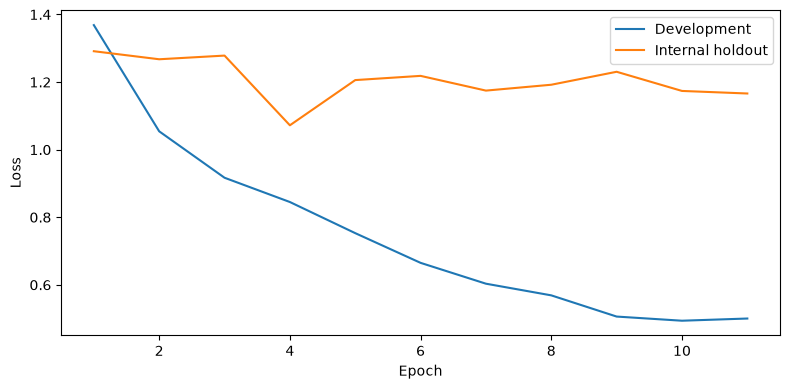

In [10]:
history_df=pd.DataFrame(history)
plt.figure(figsize=(8,4));plt.plot(history_df.epoch,history_df.train_loss,label='Development')
plt.plot(history_df.epoch,history_df.internal_holdout_loss,label='Internal holdout')
plt.xlabel('Epoch');plt.ylabel('Loss');plt.legend();plt.tight_layout()
plt.savefig(ARTIFACT_DIR/'training_history.png',dpi=160);plt.show()


## Export EF predictions for split conformal calibration

In [11]:
# Reload the dataset module so this export uses pin_memory=False, even if
# the notebook kernel imported an older version before the layout update.
import importlib
import src.datasets.panecho_echonet_dataset as panecho_dataset
importlib.reload(panecho_dataset)
build_panecho_loaders=panecho_dataset.build_panecho_loaders
payload=torch.load(OUTPUT_CHECKPOINT,map_location='cpu',weights_only=True)
model.load_state_dict(payload['model_state_dict']);model.to(DEVICE).eval()
if torch.cuda.is_available():torch.cuda.empty_cache()
model_sha256=file_sha256(OUTPUT_CHECKPOINT)
# Recreate inference loaders with no multiprocessing or pinned memory.
calibration_loader=build_panecho_loaders(manifest=calibration_records,project_root=PROJECT_ROOT,batch_size=1,
 seed=SEED,eval_num_clips=1,num_workers=0,augment=False)['test']
test_loader=build_panecho_loaders(manifest=test_records,project_root=PROJECT_ROOT,batch_size=1,
 seed=SEED,eval_num_clips=1,num_workers=0,augment=False)['test']
@torch.inference_mode()
def predict_ef(loader):
    rows=[]
    for batch in loader:
        video=batch['video'].to(DEVICE,non_blocking=False)
        if video.ndim==6:
            b,n=video.shape[:2];pred=model(video.flatten(0,1))['EF'].reshape(b,n,-1).mean(1).reshape(-1)
        else:pred=model(video)['EF'].reshape(-1)
        for path,y,p in zip(batch['video_path'],batch['ef'].cpu().numpy().reshape(-1),pred.float().cpu().numpy().reshape(-1)):
            rows.append({'video_path':str(path),'EF_true':float(y),'EF_pred':float(p),'base_model_sha256':model_sha256})
    return pd.DataFrame(rows)
cal=predict_ef(calibration_loader);test=predict_ef(test_loader)
cal.to_csv(ARTIFACT_DIR/'validation_predictions.csv',index=False);test.to_csv(ARTIFACT_DIR/'test_predictions.csv',index=False)
pd.concat([train_records[['video_path']].assign(split='development'),
 selection_records[['video_path']].assign(split='internal_holdout'),
 calibration_records[['video_path']].assign(split='calibration'),
 test_records[['video_path']].assign(split='test')],ignore_index=True).to_csv(ARTIFACT_DIR/'split_manifest.csv',index=False)
print('Calibration:',len(cal),'Test:',len(test),'Output:',ARTIFACT_DIR)


Calibration: 204 Test: 182 Output: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\03_training\echo\echonet\selected_panecho\v1
